# Analisis Ekspresi Gen untuk Klasifikasi Kanker dan Pengelompokan Sampel Berbasis Machine Learning

**Dataset:** NCBI GEO GSE9476 (Affymetrix HG-U133A)

**Deskripsi.** Proyek ini memanfaatkan data aktivitas (ekspresi) ribuan gen dari basis data terbuka NCBI GEO (GSE9476) untuk membedakan sampel leukemia mieloid akut (AML) dari sel sumsum tulang/darah normal menggunakan pembelajaran mesin. Sel kanker memiliki pola aktivitas gen yang berbeda dari sel normal, tetapi jumlah fitur (±22 ribu probe) jauh lebih banyak daripada jumlah sampel pasien (64 sampel). Karena itu analisis ini menerapkan pemodelan terarah (supervised) dengan seleksi fitur untuk menyaring gen penanda biologis (biomarker) utama, sekaligus metode pengelompokan tanpa arahan (unsupervised: PCA, K-Means, Hierarchical Clustering) untuk melihat apakah sampel kanker dan normal terpisah secara alami, lalu membandingkannya dengan literatur medis.

**Topik:** Klasifikasi AML (*acute myeloid leukemia*) vs sel hematopoietik normal dari data microarray Affymetrix HG-U133A, plus analisis unsupervised (PCA, K-Means, Hierarchical Clustering) dan interpretasi gen.

**Dataset:** GSE9476 (NCBI GEO, dataset pilihan #5: *Gene expression*). File mentah `GSE9476_RAW.tar` berisi 64 file `.CEL` tanpa label kelas. Label dan matriks ekspresi diambil dari *series matrix* GEO (lihat Tahap 2).

> **Cara menjalankan:** butuh internet pada run pertama (mengunduh `GSE9476_series_matrix.txt.gz` dan anotasi `GPL96.annot.gz`). Bila tidak ada internet, unduh kedua file secara manual lalu taruh di folder `data/`. Jalankan dengan *Restart & Run All*.

In [ ]:
import os, re, gzip, io, urllib.request, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

from sklearn.model_selection import (train_test_split, cross_validate, StratifiedKFold,
                                     GridSearchCV, permutation_test_score)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold, SelectKBest, f_classif
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import (classification_report, ConfusionMatrixDisplay, RocCurveDisplay,
                             roc_auc_score, silhouette_score, adjusted_rand_score,
                             normalized_mutual_info_score)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid", context="notebook")

DATA_DIR = Path(os.environ.get("DATA_DIR", "../data"))
FIG_DIR  = Path(os.environ.get("FIG_DIR", "../figures"))
RES_DIR  = Path(os.environ.get("RES_DIR", "../results"))
for d in (DATA_DIR, FIG_DIR, RES_DIR): d.mkdir(parents=True, exist_ok=True)

WARNA = {"AML": "#d62728", "Normal": "#1f77b4", "MDS": "#ff7f0e"}

## Tahap 1 — Pendefinisian Masalah

**Pertanyaan biologis/klinis.** Apakah profil ekspresi gen sumsum tulang dapat membedakan sampel AML dari sel hematopoietik normal, dan gen mana yang paling berperan membedakannya?

**Mengapa penting.** AML adalah keganasan darah yang heterogen dan agresif. Penanda ekspresi gen berguna untuk (1) diagnosis dan klasifikasi molekuler, (2) memahami jalur biologis yang terganggu, dan (3) kandidat target terapi atau biomarker. Data ekspresi bersifat *high-dimensional* (puluhan ribu gen, hanya puluhan sampel), sehingga risiko *overfitting* dan *data leakage* tinggi. Ini membuatnya contoh yang baik untuk praktik ML yang disiplin.

**Jenis tugas.**
- *Supervised:* klasifikasi biner **AML (1) vs Normal (0)**.
- *Unsupervised:* PCA, K-Means, dan Hierarchical Clustering pada seluruh sampel tanpa memakai label, lalu dibandingkan dengan label dan metadata sel.

**Metrik utama: ROC-AUC**, didampingi F1 (kelas AML), *balanced accuracy*, dan akurasi.
Alasan: kelas tidak seimbang dan sampel sedikit, sehingga akurasi mudah menyesatkan (model yang selalu menebak kelas mayoritas sudah tampak "bagus"). AUC tidak bergantung pada satu ambang keputusan dan menilai kemampuan memisahkan kedua kelas. F1 dan sensitivitas kelas AML penting secara klinis karena *false negative* (AML terlewat) lebih berbahaya.

## Tahap 2 — Exploratory Data Analysis (EDA)

### 2.1 Mengambil data
`GSE9476_RAW.tar` (CEL mentah) tidak memuat label kelas. Karena itu, label dan matriks ekspresi (probe × sampel, sudah dinormalisasi) diambil dari *series matrix* GEO. Opsi B: bila ingin memakai CEL Anda sendiri, jalankan `r/rma_from_cel.R` (RMA di R/Bioconductor) lalu set `USE_RMA_DARI_CEL = True` di bawah.

In [ ]:
URL_SM  = "https://ftp.ncbi.nlm.nih.gov/geo/series/GSE9nnn/GSE9476/matrix/GSE9476_series_matrix.txt.gz"
URL_GPL = "https://ftp.ncbi.nlm.nih.gov/geo/platforms/GPL96nnn/GPL96/annot/GPL96.annot.gz"
F_SM, F_GPL = DATA_DIR/"GSE9476_series_matrix.txt.gz", DATA_DIR/"GPL96.annot.gz"
USE_RMA_DARI_CEL = False   # True -> pakai data/GSE9476_rma.csv hasil r/rma_from_cel.R

def unduh(url, tujuan):
    if tujuan.exists(): return True
    try:
        print("Mengunduh", url); urllib.request.urlretrieve(url, tujuan); return True
    except Exception as e:
        print(f"GAGAL mengunduh ({e}). Unduh manual lalu simpan sebagai {tujuan}")
        return False

ok_sm = unduh(URL_SM, F_SM)
ok_gpl = unduh(URL_GPL, F_GPL)
assert ok_sm, "File series matrix wajib ada (label kelas ada di sini)."

Mengunduh https://ftp.ncbi.nlm.nih.gov/geo/series/GSE9nnn/GSE9476/matrix/GSE9476_series_matrix.txt.gz
Mengunduh https://ftp.ncbi.nlm.nih.gov/geo/platforms/GPL96nnn/GPL96/annot/GPL96.annot.gz
GAGAL mengunduh (HTTP Error 404: Not Found). Unduh manual lalu simpan sebagai ../data/GPL96.annot.gz


In [ ]:
def baca_series_matrix(path):
    meta, tabel, dalam = {}, [], False
    with gzip.open(path, "rt", errors="ignore") as f:
        for line in f:
            line = line.rstrip("\n")
            if line.startswith("!series_matrix_table_begin"): dalam = True; continue
            if line.startswith("!series_matrix_table_end"):   dalam = False; continue
            if dalam: tabel.append(line)
            elif line.startswith("!Sample_"):
                p = line.split("\t"); meta.setdefault(p[0][len("!Sample_"):], []).append([v.strip('"') for v in p[1:]])
    expr = pd.read_csv(io.StringIO("\n".join(tabel)), sep="\t", index_col=0)
    expr.columns = [c.strip('"') for c in expr.columns]; expr.index = expr.index.astype(str).str.strip('"')
    acc = meta["geo_accession"][0]; n = len(acc)
    md_ = pd.DataFrame(index=acc)
    md_["title"]  = meta.get("title", [[""]*n])[0]
    md_["source"] = meta.get("source_name_ch1", [[""]*n])[0]
    ch = meta.get("characteristics_ch1", [])
    md_["karakteristik"] = [" | ".join(v) for v in zip(*ch)] if ch else [""]*n
    return expr, md_

def baca_anotasi(path):
    with gzip.open(path, "rt", errors="ignore") as f:
        baris = [l for l in f if not l.startswith(("^", "!", "#"))]
    return pd.read_csv(io.StringIO("".join(baris)), sep="\t", index_col=0, low_memory=False)

expr, meta = baca_series_matrix(F_SM)
if USE_RMA_DARI_CEL:
    rma = pd.read_csv(DATA_DIR/"GSE9476_rma.csv", index_col=0)
    rma.columns = [c.split(".")[0] for c in rma.columns]
    expr = rma[meta.index]
expr = expr[meta.index]                       # samakan urutan sampel
anot = baca_anotasi(F_GPL) if F_GPL.exists() else None
print("Matriks ekspresi (probe x sampel):", expr.shape)
meta.head(10)

Matriks ekspresi (probe x sampel): (22283, 64)


,title,source,karakteristik
GSM239170,BM_CD34_R000030,Bone Marrow CD34+ selected cells,Bone Marrow CD34+ selected cells | Unknown age...
GSM239323,BM_01000,Bone Marrow,Bone Marrow Mononuclear Cells | Unknown Age | ...
GSM239324,BM_02300,Bone Marrow,Bone Marrow Mononuclear Cells | 31y Male | | ...
GSM239326,BM_02303,Bone Marrow,Bone Marrow Mononuclear Cells | 27y Male | | ...
GSM239328,BM_02347,Bone Marrow,Bone Marrow Mononuclear Cells | 26y Female | ...
GSM239329,BM_02417,Bone Marrow,Bone Marrow Mononuclear Cells | Unknown Age/Un...
GSM239331,BM_02496,Bone Marrow,Bone Marrow Mononuclear Cells | 24y Male | | ...
GSM239332,BM_02619,Bone Marrow,Bone Marrow Mononuclear Cells | 35y Male | | ...
GSM239333,BM_02680,Bone Marrow,Bone Marrow Mononuclear Cells | 24y Female | ...
GSM239334,BM_02879,Bone Marrow,Bone Marrow Mononuclear Cells | 22y Male | | ...


### 2.2 Menentukan label kelas dari metadata GEO
Label dibuat dengan *regex* pada judul/sumber/karakteristik sampel. **Wajib diperiksa manual** pada tabel silang di bawah: jika ada sampel yang salah kelompok, perbaiki aturan regex-nya.

In [ ]:
def kelompok(teks):
    t = teks.lower()
    if re.search(r"\bmds\b|myelodysplas", t):                      return "MDS"
    if re.search(r"\baml\b|acute myeloid|leuk[a]?emi", t):         return "AML"
    return "Normal"

def subtipe(teks, grp):
    t = teks.lower()
    if grp != "Normal": return grp
    if "cd34" in t:                                        return "Normal-CD34+"
    if re.search(r"pbsc|peripheral", t):                   return "Normal-PBSC"
    if re.search(r"nbm|bmmnc|bone marrow|\bbm\b|mnc", t): return "Normal-BM"
    return "Normal-lain"

meta["teks"] = (meta["title"] + " " + meta["source"] + " " + meta["karakteristik"])
meta["kelompok"] = meta["teks"].apply(kelompok)
meta["subtipe"]  = [subtipe(t, g) for t, g in zip(meta["teks"], meta["kelompok"])]

print(meta["kelompok"].value_counts(), "\n")
pd.set_option("display.max_colwidth", 80, "display.width", 200)
print(pd.crosstab(meta["title"].str.replace(r"\d+", "#", regex=True), meta["kelompok"]).head(30))
assert meta["kelompok"].nunique() >= 2, "Label < 2 kelas: periksa aturan regex di atas."

kelompok
Normal    38
AML       19
MDS        7
Name: count, dtype: int64 

kelompok       AML  MDS  Normal
title                          
BM_#             0    0      10
BM_CD#_R#        0    0       2
BM_CD#_TBO#      0    0       6
FHCRCAML#       19    6       0
FHCRCAML_#       0    1       0
PBSC_CD#_K#      0    0       3
PBSC_CD#_KO#     0    0       1
PBSC_CD#_R#      0    0       5
PBSC_CD#_R#-#    0    0       1
PB_DON#          0    0      10


### 2.3 Ukuran data, tipe fitur, missing value

In [ ]:
# Buang probe kontrol Affymetrix (AFFX-*) lalu transpos: baris = sampel, kolom = probe
expr = expr.loc[~expr.index.str.startswith("AFFX")]
print("Jumlah sampel :", expr.shape[1], "| jumlah probe :", expr.shape[0])
print("Tipe data     :", expr.dtypes.unique())
print("Missing value :", int(expr.isna().sum().sum()))
print("Rentang nilai :", float(expr.min().min()), "-", float(expr.max().max()))

# Pastikan skala log2 (microarray: nilai mentah bisa puluhan ribu)
if expr.max().max() > 50:
    print("Nilai tampak belum berskala log -> log2(x+1)")
    expr = np.log2(expr.clip(lower=0) + 1)
X_all = expr.T                       # sampel x probe
print("X_all:", X_all.shape)

Jumlah sampel : 64 | jumlah probe : 22215
Tipe data     : [dtype('float64')]
Missing value : 0
Rentang nilai : 0.773024698 - 15.73261114
X_all: (64, 22215)


### 2.4 Visualisasi (4 gambar)

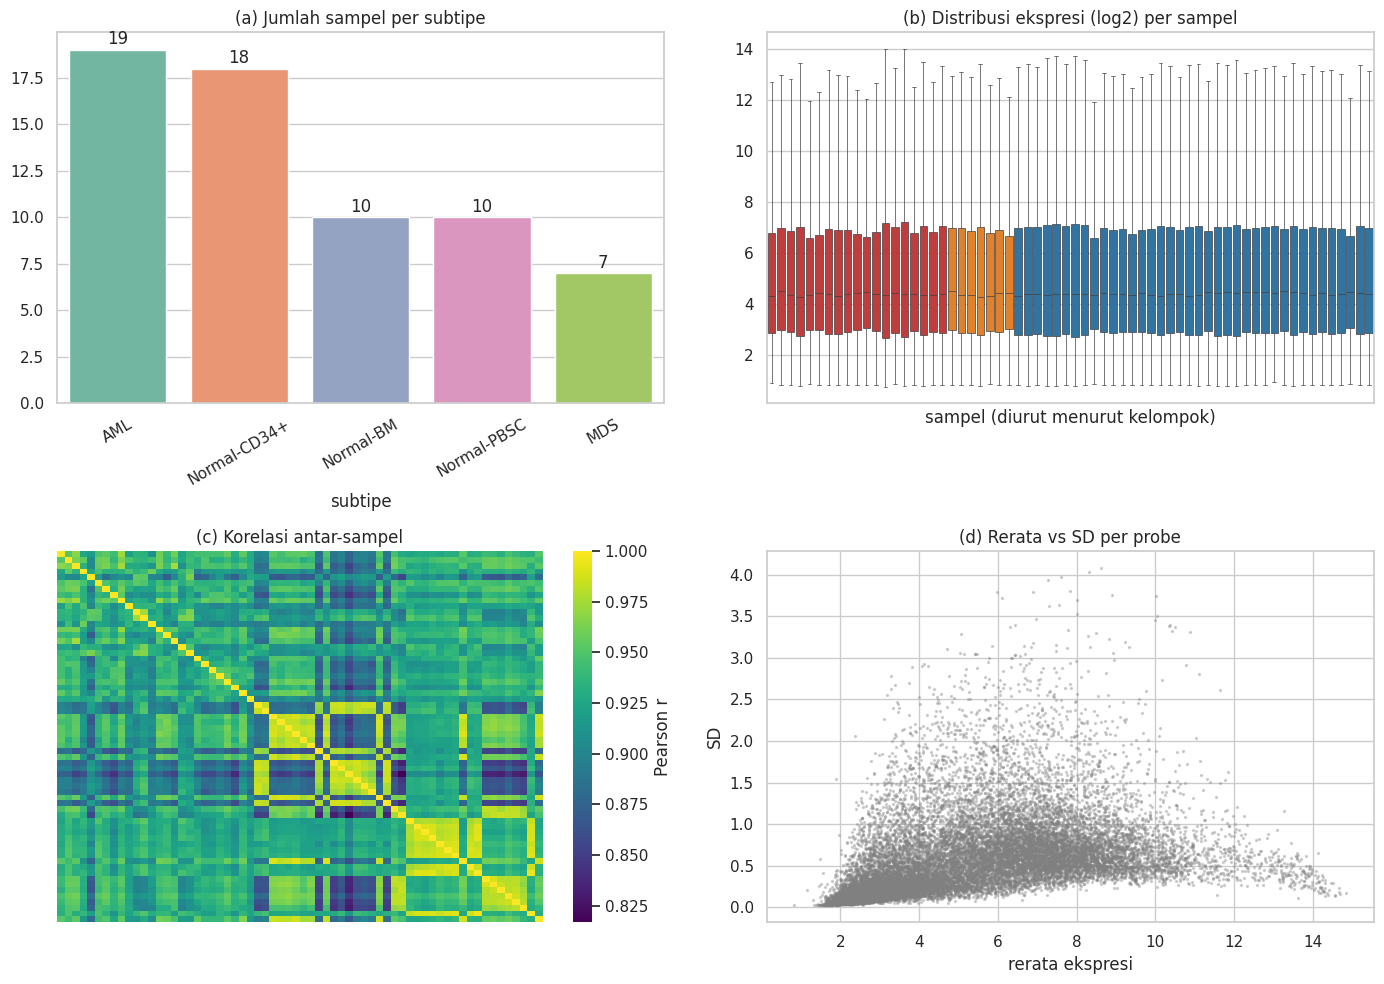

In [ ]:
fig, ax = plt.subplots(2, 2, figsize=(14, 10))

# (a) Proporsi kelas
vc = meta["subtipe"].value_counts()
sns.barplot(x=vc.index, y=vc.values, ax=ax[0,0], palette="Set2")
for i, v in enumerate(vc.values): ax[0,0].text(i, v+0.3, str(v), ha="center")
ax[0,0].set_title("(a) Jumlah sampel per subtipe"); ax[0,0].tick_params(axis="x", rotation=30)

# (b) Distribusi intensitas per sampel (cek kualitas / efek batch)
urut = meta.sort_values("kelompok").index
sns.boxplot(data=X_all.loc[urut].T, ax=ax[0,1], showfliers=False,
            palette=[WARNA[meta.loc[s,"kelompok"]] for s in urut], linewidth=0.5)
ax[0,1].set_xticks([]); ax[0,1].set_title("(b) Distribusi ekspresi (log2) per sampel"); ax[0,1].set_xlabel("sampel (diurut menurut kelompok)")

# (c) Korelasi antar-sampel
C = X_all.loc[urut].T.corr()
sns.heatmap(C, ax=ax[1,0], cmap="viridis", xticklabels=False, yticklabels=False, cbar_kws={"label": "Pearson r"})
ax[1,0].set_title("(c) Korelasi antar-sampel")

# (d) Mean vs SD tiap probe
mu, sd = X_all.mean(), X_all.std()
ax[1,1].scatter(mu, sd, s=2, alpha=0.3, color="gray")
ax[1,1].set_xlabel("rerata ekspresi"); ax[1,1].set_ylabel("SD"); ax[1,1].set_title("(d) Rerata vs SD per probe")
plt.tight_layout(); plt.savefig(FIG_DIR/"eda.png", dpi=150); plt.show()

**Catatan EDA (isi setelah melihat gambar):** apakah kelas seimbang? apakah ada sampel dengan distribusi menyimpang (kandidat *outlier*/batch)? apakah sampel sekelompok cenderung berkorelasi tinggi satu sama lain?

## Tahap 3 — Preprocessing

Semua langkah yang "belajar dari data" dimasukkan ke dalam **`Pipeline`** supaya hanya dipelajari dari data latih di setiap lipatan CV (tanpa *data leakage*):
`SimpleImputer(median)` → `VarianceThreshold` → `StandardScaler` → `SelectKBest(f_classif)` → model.

Seleksi gen (`SelectKBest`) **harus** berada di dalam pipeline. Memilih gen dari seluruh data sebelum CV adalah sumber kebocoran paling umum pada data ekspresi gen.

Data supervised memakai sampel **AML dan Normal** saja (MDS dikeluarkan karena kelas ketiga terlalu sedikit/heterogen; MDS tetap dipakai di Tahap 5). Split 80/20 dengan `stratify`.

In [ ]:
mask = meta["kelompok"].isin(["AML", "Normal"])
X = X_all.loc[mask]
y = (meta.loc[mask, "kelompok"] == "AML").astype(int)      # 1 = AML, 0 = Normal
print("Sampel supervised:", X.shape, "| AML:", int(y.sum()), "| Normal:", int((y==0).sum()))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, "| Test:", X_test.shape, "| AML di test:", int(y_test.sum()))

def buat(clf, k=200):
    return Pipeline([("imp", SimpleImputer(strategy="median")),
                     ("var", VarianceThreshold(1e-6)),
                     ("scale", StandardScaler()),
                     ("sel", SelectKBest(f_classif, k=k)),
                     ("clf", clf)])

def skor(model, Xd):
    return model.decision_function(Xd) if hasattr(model, "decision_function") else model.predict_proba(Xd)[:, 1]

cv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
assert y_train.value_counts().min() >= 5, "Kelas minoritas di train < 5: kurangi n_splits."

Sampel supervised: (57, 22215) | AML: 19 | Normal: 38
Train: (45, 22215) | Test: (12, 22215) | AML di test: 4


## Tahap 4 — Supervised Learning

Empat model dibandingkan dengan 5-fold stratified CV pada **data latih saja**: baseline (`DummyClassifier`, selalu menebak kelas mayoritas), regresi logistik L2, SVM linear, dan Random Forest. Model linear dipilih karena sangat cocok untuk data p ≫ n dan mudah diinterpretasi.

In [ ]:
modelz = {
    "Baseline (Dummy)": buat(DummyClassifier(strategy="most_frequent")),
    "LogReg L2":        buat(LogisticRegression(C=0.1, max_iter=5000)),
    "SVM linear":       buat(SVC(kernel="linear", C=0.1)),
    "RandomForest":     buat(RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE)),
}
metrik = ["accuracy", "balanced_accuracy", "f1", "roc_auc"]
baris, mentah = [], {}
for nama, m in modelz.items():
    s = cross_validate(m, X_train, y_train, cv=cv, scoring=metrik)
    mentah[nama] = s
    baris.append({"model": nama, **{k: f"{s['test_'+k].mean():.3f} ± {s['test_'+k].std():.3f}" for k in metrik},
                  "_auc": s["test_roc_auc"].mean(), "_f1": s["test_f1"].mean()})
hasil_cv = pd.DataFrame(baris).sort_values(["_auc", "_f1"], ascending=False).reset_index(drop=True)
hasil_cv.drop(columns=["_auc", "_f1"]).to_csv(RES_DIR/"cv_model_comparison.csv", index=False)
hasil_cv.drop(columns=["_auc", "_f1"])

,model,accuracy,balanced_accuracy,f1,roc_auc
0,SVM linear,0.978 ± 0.044,0.967 ± 0.067,0.960 ± 0.080,0.989 ± 0.022
1,RandomForest,0.978 ± 0.044,0.967 ± 0.067,0.960 ± 0.080,0.989 ± 0.022
2,LogReg L2,0.978 ± 0.044,0.967 ± 0.067,0.960 ± 0.080,0.978 ± 0.044
3,Baseline (Dummy),0.667 ± 0.000,0.500 ± 0.000,0.000 ± 0.000,0.500 ± 0.000


### 4.2 Tuning hyperparameter model terbaik (GridSearchCV, metrik = ROC-AUC)

In [ ]:
grids = {
    "LogReg L2":    {"sel__k": [50, 200, 1000], "clf__C": [0.001, 0.01, 0.1, 1]},
    "SVM linear":   {"sel__k": [50, 200, 1000], "clf__C": [0.001, 0.01, 0.1, 1]},
    "RandomForest": {"sel__k": [50, 200, 1000], "clf__max_depth": [None, 5], "clf__min_samples_leaf": [1, 3]},
}
kandidat = hasil_cv[hasil_cv["model"] != "Baseline (Dummy)"]
terbaik = kandidat.iloc[0]["model"]
print("Model terbaik menurut CV:", terbaik)

gs = GridSearchCV(modelz[terbaik], grids[terbaik], cv=cv, scoring="roc_auc", n_jobs=-1, refit=True)
gs.fit(X_train, y_train)
print("Parameter terbaik:", gs.best_params_, "| AUC CV:", round(gs.best_score_, 3))

Model terbaik menurut CV: SVM linear
Parameter terbaik: {'clf__C': 0.001, 'sel__k': 50} | AUC CV: 0.989


### 4.3 Estimasi performa yang lebih jujur: nested CV + uji permutasi label
Set test hanya berisi belasan sampel, sehingga satu sampel salah dapat mengubah metrik banyak. Dua pemeriksaan tambahan, keduanya hanya memakai data latih:
- **Nested CV:** tuning di *inner loop*, evaluasi di *outer loop*.
- **Uji permutasi label:** jika label diacak, AUC harus turun ke ~0,5. Jika tidak, ada indikasi *leakage*.

In [ ]:
outer = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE + 1)
inner = StratifiedKFold(3, shuffle=True, random_state=RANDOM_STATE + 2)
nested = cross_validate(GridSearchCV(modelz[terbaik], grids[terbaik], cv=inner, scoring="roc_auc", n_jobs=-1),
                        X_train, y_train, cv=outer, scoring=["roc_auc", "f1", "balanced_accuracy"])
for k in ["roc_auc", "f1", "balanced_accuracy"]:
    print(f"Nested CV {k:18s}: {nested['test_'+k].mean():.3f} ± {nested['test_'+k].std():.3f}")

auc_asli, auc_perm, pval = permutation_test_score(gs.best_estimator_, X_train, y_train, cv=cv,
                                                  scoring="roc_auc", n_permutations=50,
                                                  random_state=RANDOM_STATE, n_jobs=-1)
print(f"AUC label asli = {auc_asli:.3f} | AUC label diacak = {auc_perm.mean():.3f} ± {auc_perm.std():.3f} | p = {pval:.3f}")

Nested CV roc_auc           : 1.000 ± 0.000
Nested CV f1                : 0.920 ± 0.098
Nested CV balanced_accuracy : 0.933 ± 0.082
AUC label asli = 0.989 | AUC label diacak = 0.503 ± 0.130 | p = 0.020


### 4.4 Evaluasi akhir pada data test (dilakukan **sekali saja**)

              precision    recall  f1-score   support

      Normal       0.89      1.00      0.94         8
         AML       1.00      0.75      0.86         4

    accuracy                           0.92        12
   macro avg       0.94      0.88      0.90        12
weighted avg       0.93      0.92      0.91        12

ROC-AUC test: 1.0


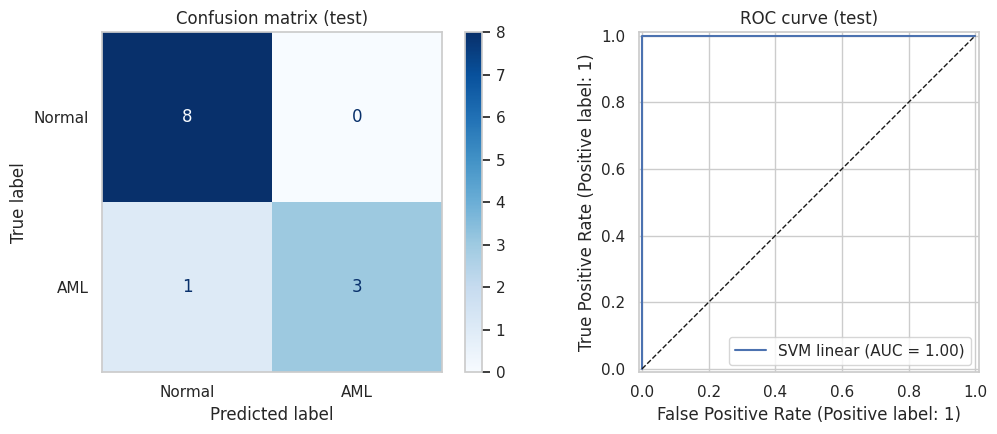

In [ ]:
y_pred = gs.predict(X_test)
s_test = skor(gs.best_estimator_, X_test)
print(classification_report(y_test, y_pred, target_names=["Normal", "AML"]))
print("ROC-AUC test:", round(roc_auc_score(y_test, s_test), 3))

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["Normal", "AML"], cmap="Blues", ax=ax[0])
ax[0].set_title("Confusion matrix (test)"); ax[0].grid(False)
RocCurveDisplay.from_predictions(y_test, s_test, ax=ax[1], name=terbaik)
ax[1].plot([0, 1], [0, 1], "k--", lw=1); ax[1].set_title("ROC curve (test)")
plt.tight_layout(); plt.savefig(FIG_DIR/"evaluasi_test.png", dpi=150); plt.show()

**Peringatan:** akurasi/AUC mendekati 100% pada data ekspresi gen **tidak otomatis berarti ada kebocoran**. Perbedaan AML vs normal memang kuat secara biologis. Namun hasil sebagus itu pada n kecil tetap harus dicurigai. Gunakan hasil uji permutasi dan nested CV di atas sebagai bukti bahwa pipeline bersih, dan jelaskan di Tahap 7.

## Tahap 5 — Unsupervised Learning

Seluruh sampel (AML, Normal, MDS bila ada) dipakai **tanpa label**. Untuk mengurangi *noise*, dipilih 2.000 probe dengan variansi tertinggi. Pemilihan ini tidak memakai label sehingga bukan kebocoran, lalu data distandarisasi.

Variansi dijelaskan PC1..PC5: [0.399 0.121 0.097 0.046 0.038] | kumulatif 2 PC: 0.52 | kumulatif 10 PC: 0.799


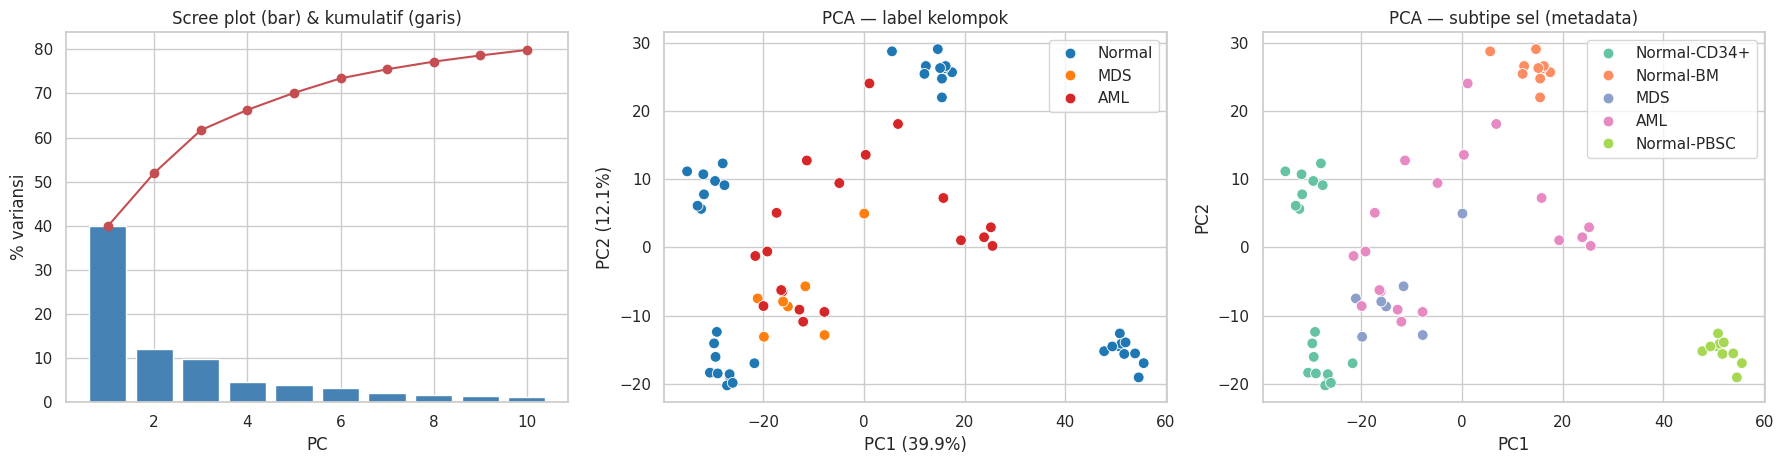

In [ ]:
top_var = X_all.var().sort_values(ascending=False).index[:2000]
Z = StandardScaler().fit_transform(X_all[top_var])

# --- PCA ---
pca = PCA(n_components=10, random_state=RANDOM_STATE).fit(Z)
Xp = pca.transform(Z)
ev = pca.explained_variance_ratio_
print("Variansi dijelaskan PC1..PC5:", np.round(ev[:5], 3), "| kumulatif 2 PC:", round(ev[:2].sum(), 3),
      "| kumulatif 10 PC:", round(ev.sum(), 3))

fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
ax[0].bar(range(1, 11), ev*100, color="steelblue"); ax[0].plot(range(1, 11), np.cumsum(ev)*100, "ro-")
ax[0].set_xlabel("PC"); ax[0].set_ylabel("% variansi"); ax[0].set_title("Scree plot (bar) & kumulatif (garis)")
sns.scatterplot(x=Xp[:, 0], y=Xp[:, 1], hue=meta["kelompok"].values, palette=WARNA, s=60, ax=ax[1])
ax[1].set_xlabel(f"PC1 ({ev[0]*100:.1f}%)"); ax[1].set_ylabel(f"PC2 ({ev[1]*100:.1f}%)"); ax[1].set_title("PCA — label kelompok")
sns.scatterplot(x=Xp[:, 0], y=Xp[:, 1], hue=meta["subtipe"].values, palette="Set2", s=60, ax=ax[2])
ax[2].set_xlabel("PC1"); ax[2].set_ylabel("PC2"); ax[2].set_title("PCA — subtipe sel (metadata)")
plt.tight_layout(); plt.savefig(FIG_DIR/"pca.png", dpi=150); plt.show()

### 5.2 K-Means: memilih K (elbow + silhouette)

Silhouette per K: {2: np.float64(0.287), 3: np.float64(0.294), 4: np.float64(0.33), 5: np.float64(0.297), 6: np.float64(0.31), 7: np.float64(0.318), 8: np.float64(0.32)} -> K terbaik (silhouette) = 4


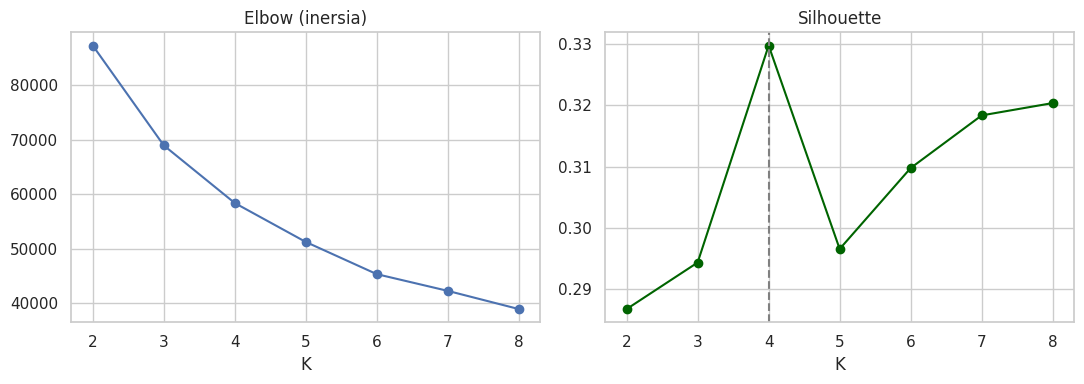

   K  silhouette  ARI vs kelompok  NMI vs kelompok  ARI vs subtipe
0  3       0.294           -0.029            0.118           0.377
1  4       0.330            0.062            0.310           0.455

Cluster K-Means (K=3) vs subtipe
subtipe  AML  MDS  Normal-BM  Normal-CD34+  Normal-PBSC
km3                                                    
0         10    6          0            18            0
1          9    1         10             0            0
2          0    0          0             0           10

Cluster K-Means (K=4) vs subtipe
subtipe  AML  MDS  Normal-BM  Normal-CD34+  Normal-PBSC
km4                                                    
0          9    1          0             0            0
1         10    6          0            18            0
2          0    0         10             0            0
3          0    0          0             0           10


In [ ]:
Ks = range(2, 9); inersia, sil = [], []
for k in Ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Z)
    inersia.append(km.inertia_); sil.append(silhouette_score(Z, km.labels_))
K_best = list(Ks)[int(np.argmax(sil))]
print("Silhouette per K:", dict(zip(Ks, np.round(sil, 3))), "-> K terbaik (silhouette) =", K_best)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(list(Ks), inersia, "o-"); ax[0].set_title("Elbow (inersia)"); ax[0].set_xlabel("K")
ax[1].plot(list(Ks), sil, "o-", color="darkgreen"); ax[1].axvline(K_best, ls="--", color="gray")
ax[1].set_title("Silhouette"); ax[1].set_xlabel("K")
plt.tight_layout(); plt.savefig(FIG_DIR/"kmeans_k.png", dpi=150); plt.show()

# Bandingkan dengan label asli & metadata untuk K terbaik dan K = jumlah kelompok
n_grup = meta["kelompok"].nunique(); baris = []
for k in sorted({K_best, n_grup}):
    lab = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(Z)
    meta[f"km{k}"] = lab
    baris.append({"K": k, "silhouette": round(silhouette_score(Z, lab), 3),
                  "ARI vs kelompok": round(adjusted_rand_score(meta["kelompok"], lab), 3),
                  "NMI vs kelompok": round(normalized_mutual_info_score(meta["kelompok"], lab), 3),
                  "ARI vs subtipe":  round(adjusted_rand_score(meta["subtipe"], lab), 3)})
tab_km = pd.DataFrame(baris); tab_km.to_csv(RES_DIR/"kmeans_vs_label.csv", index=False); print(tab_km)
for k in sorted({K_best, n_grup}):
    print(f"\nCluster K-Means (K={k}) vs subtipe"); print(pd.crosstab(meta[f"km{k}"], meta["subtipe"]))

### 5.3 Hierarchical clustering (Ward)

Hierarchical (K=4): ARI vs kelompok = 0.030, ARI vs subtipe = 0.432
subtipe  AML  MDS  Normal-BM  Normal-CD34+  Normal-PBSC
hc                                                     
1         11    7          0            18            0
2          0    0          0             0           10
3          0    0         10             0            0
4          8    0          0             0            0


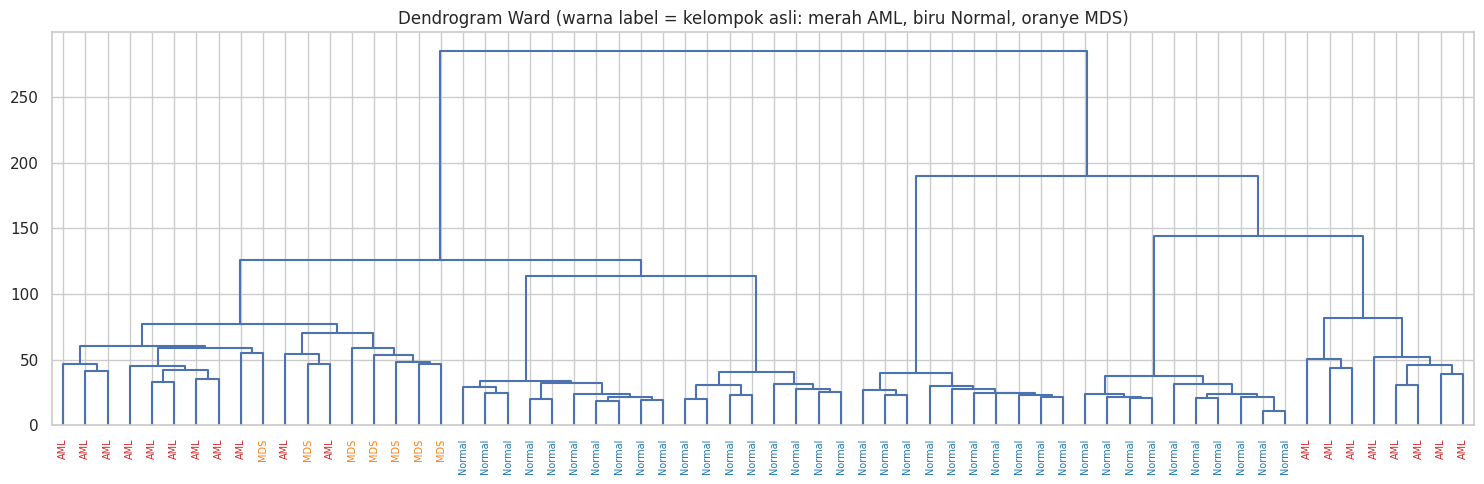

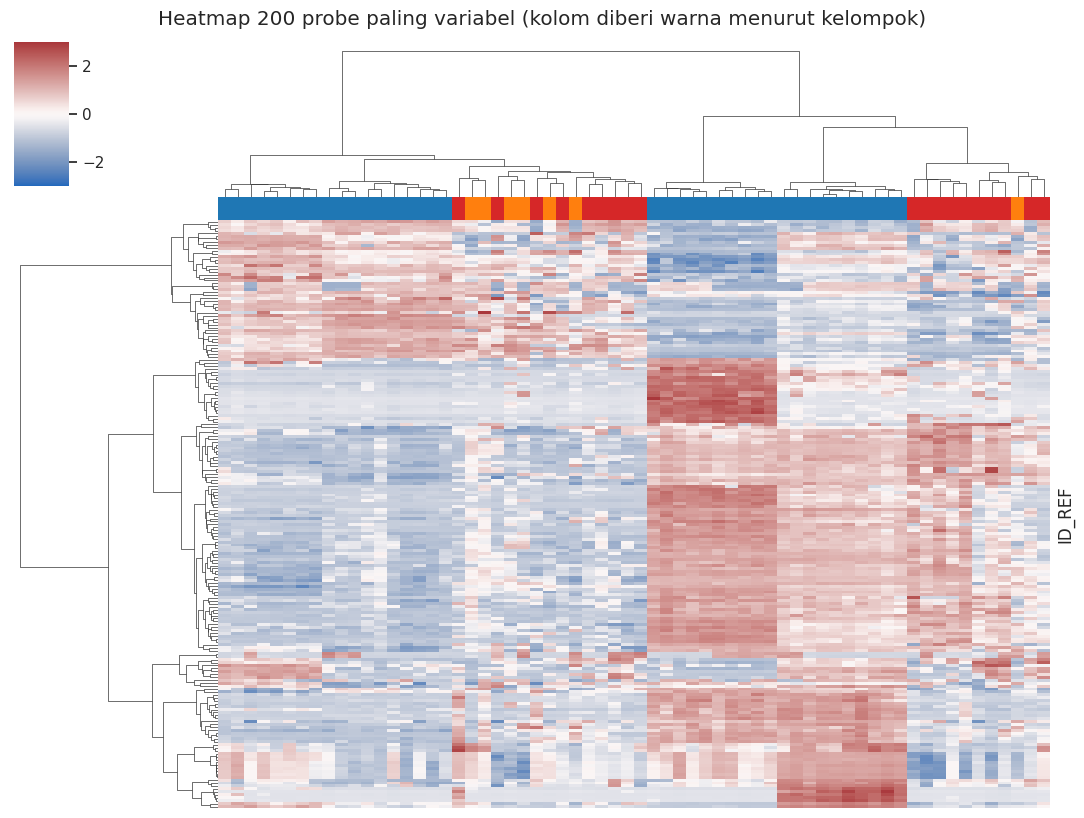

In [ ]:
L = linkage(Z, method="ward")
K_h = K_best
meta["hc"] = fcluster(L, t=K_h, criterion="maxclust")
print(f"Hierarchical (K={K_h}): ARI vs kelompok = {adjusted_rand_score(meta['kelompok'], meta['hc']):.3f}, "
      f"ARI vs subtipe = {adjusted_rand_score(meta['subtipe'], meta['hc']):.3f}")
print(pd.crosstab(meta["hc"], meta["subtipe"]))

fig, ax = plt.subplots(figsize=(15, 5))
d = dendrogram(L, labels=meta["kelompok"].values, leaf_rotation=90, leaf_font_size=7, ax=ax, color_threshold=0)
for lbl in ax.get_xmajorticklabels(): lbl.set_color(WARNA[lbl.get_text()])
ax.set_title("Dendrogram Ward (warna label = kelompok asli: merah AML, biru Normal, oranye MDS)")
plt.tight_layout(); plt.savefig(FIG_DIR/"dendrogram.png", dpi=150); plt.show()

# Heatmap 200 gen paling variabel
Zh = pd.DataFrame(StandardScaler().fit_transform(X_all[top_var[:200]]), index=X_all.index, columns=top_var[:200])
cg = sns.clustermap(Zh.T, method="ward", cmap="vlag", center=0, vmin=-3, vmax=3,
                    col_colors=meta["kelompok"].map(WARNA).values, xticklabels=False, yticklabels=False,
                    figsize=(11, 8))
cg.fig.suptitle("Heatmap 200 probe paling variabel (kolom diberi warna menurut kelompok)", y=1.02)
cg.savefig(FIG_DIR/"clustermap.png", dpi=150); plt.show()

**Catatan:** bandingkan hasil klaster dengan label. Apakah AML dan Normal terpisah di PC1/PC2? Apakah sampel Normal-CD34+ dan Normal-BM membentuk klaster berbeda? Sampel MDS berada di dekat kelompok yang mana? ARI ≈ 0 berarti klaster tidak berkaitan dengan label; ARI ≈ 1 berarti identik.

## Tahap 6 — Interpretasi

Interpretasi memakai **data latih saja** supaya tidak "mengintip" test. Tiga sumber bukti: (1) uji t Welch per probe dengan koreksi Benjamini–Hochberg, (2) koefisien regresi logistik (fitur sudah distandarisasi, sehingga koefisien sebanding), dan (3) loading PC1.

Probe signifikan (q<0.05 & |log2FC|>1): 442


,gen,probe,log2FC,q_BH,deskripsi
0,,205632_s_at,-2.476604,1.407460e-07,
1,,205726_at,1.670875,1.367791e-06,
2,,218711_s_at,-2.410248,2.621919e-05,
3,,215489_x_at,3.687719,2.896969e-05,
4,,205603_s_at,1.165883,3.146866e-05,
5,,202478_at,-3.537382,3.146866e-05,
6,,201105_at,2.479198,3.146866e-05,
7,,213506_at,-2.997862,3.146866e-05,
8,,204115_at,-1.683475,3.192474e-05,
9,,209604_s_at,-2.079556,3.208167e-05,


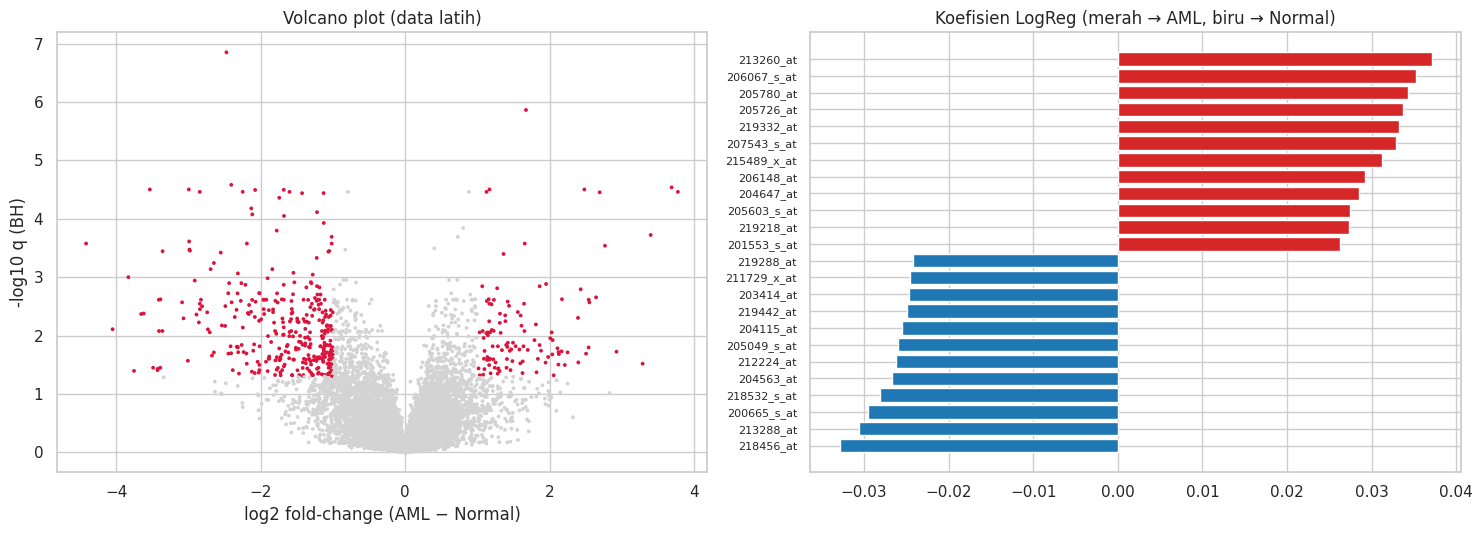

Probe dengan |loading| PC1 terbesar:
['207104_x_at', '210423_s_at', '201892_s_at', '203066_at', '204173_at', '217809_at', '210660_at', '206420_at', '222218_s_at', '208594_x_at']

Irisan 50 probe teratas DE vs LogReg: 22


In [17]:
# Anotasi probe -> simbol gen
if anot is not None and "Gene symbol" in anot.columns:
    simbol = anot["Gene symbol"].fillna("").astype(str).str.split(" /// ").str[0]
    judul  = anot["Gene title"].fillna("").astype(str) if "Gene title" in anot.columns else pd.Series("", index=anot.index)
else:
    simbol = pd.Series("", index=X_all.columns); judul = simbol.copy()
def nama(p):
    s = simbol.get(p, ""); return f"{s} ({p})" if s else p

def bh(p):
    p = np.asarray(p, float); n = len(p); o = np.argsort(p)
    q = p[o] * n / np.arange(1, n + 1)
    q = np.minimum.accumulate(q[::-1])[::-1]; out = np.empty(n); out[o] = np.minimum(q, 1); return out

# (1) Differential expression AML vs Normal (train saja)
a, n_ = X_train[y_train == 1], X_train[y_train == 0]
t, p = stats.ttest_ind(a, n_, equal_var=False)
de = pd.DataFrame({"probe": X_train.columns, "log2FC": (a.mean() - n_.mean()).values, "t": t, "p": p}).fillna({"p": 1, "t": 0})
de["q_BH"] = bh(de["p"]); de["gen"] = de["probe"].map(lambda x: simbol.get(x, "")); de["deskripsi"] = de["probe"].map(lambda x: judul.get(x, ""))
de = de.sort_values("p").reset_index(drop=True); de.to_csv(RES_DIR/"diff_expr_train.csv", index=False)
print("Probe signifikan (q<0.05 & |log2FC|>1):", int(((de.q_BH < 0.05) & (de.log2FC.abs() > 1)).sum()))
display(de.head(15)[["gen", "probe", "log2FC", "q_BH", "deskripsi"]])

fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
sig = (de.q_BH < 0.05) & (de.log2FC.abs() > 1)
ax[0].scatter(de.log2FC, -np.log10(de.q_BH.clip(lower=1e-300)), s=3, c=np.where(sig, "crimson", "lightgray"))
ax[0].set_xlabel("log2 fold-change (AML − Normal)"); ax[0].set_ylabel("-log10 q (BH)"); ax[0].set_title("Volcano plot (data latih)")

# (2) Koefisien regresi logistik pada pipeline (k=200)
lr = buat(LogisticRegression(C=0.01, max_iter=5000), k=200).fit(X_train, y_train)
nama_fitur = np.array(X_train.columns)[lr.named_steps["var"].get_support()][lr.named_steps["sel"].get_support()]
koef = pd.Series(lr.named_steps["clf"].coef_[0], index=nama_fitur).sort_values()
top = pd.concat([koef.head(12), koef.tail(12)])
ax[1].barh([nama(i) for i in top.index], top.values, color=np.where(top.values > 0, WARNA["AML"], WARNA["Normal"]))
ax[1].set_title("Koefisien LogReg (merah → AML, biru → Normal)"); ax[1].tick_params(axis="y", labelsize=8)
plt.tight_layout(); plt.savefig(FIG_DIR/"interpretasi.png", dpi=150); plt.show()

# (3) Loading PC1 (dari Tahap 5)
load = pd.Series(pca.components_[0], index=top_var).sort_values(key=np.abs, ascending=False).head(10)
print("Probe dengan |loading| PC1 terbesar:"); print([nama(i) for i in load.index])

# Irisan dua metode
top_de = set(de.head(50)["probe"]); top_lr = set(koef.abs().sort_values(ascending=False).head(50).index)
print("\nIrisan 50 probe teratas DE vs LogReg:", len(top_de & top_lr))

### 6.2 Apakah masuk akal secara biologis?
Sel AML umumnya berupa *blast* mieloid yang tertahan pada tahap imatur, sedangkan sumsum tulang normal berisi campuran sel dengan banyak sel mieloid matang. Kandidat gen dari literatur berikut dicek di hasil Anda. Daftar ini **hipotesis untuk dibandingkan**, bukan hasil: arah dan signifikansinya harus dibaca dari tabel yang dihasilkan sel di bawah.

In [ ]:
kandidat_lit = {
  "progenitor / AML": ["CD34", "KIT", "FLT3", "HOXA9", "MEIS1", "MPO", "ELANE", "AZU1", "PRTN3", "CTSG", "MYB", "CD33"],
  "mieloid matang / normal": ["S100A8", "S100A9", "LTF", "LCN2", "CAMP", "HBB", "GYPA"],
}
cek = []
for kel, daftar in kandidat_lit.items():
    for g in daftar:
        s = de[de["gen"] == g]
        if len(s):
            r = s.sort_values("p").iloc[0]
            cek.append({"kelompok_literatur": kel, "gen": g, "probe": r["probe"], "log2FC(AML-Normal)": round(r["log2FC"], 2),
                        "q_BH": float(f"{r['q_BH']:.2e}"), "peringkat_DE": int(s.sort_values("p").index[0]) + 1})
cek = pd.DataFrame(cek); cek.to_csv(RES_DIR/"cek_gen_literatur.csv", index=False)
cek if len(cek) else print("Anotasi gen tidak tersedia atau tidak ada kandidat yang cocok.")

Anotasi gen tidak tersedia atau tidak ada kandidat yang cocok.


**Rujukan literatur untuk diskusi (verifikasi sendiri sebelum dikutip):**
- Stirewalt DL, et al. (2008). *Identification of genes with abnormal expression changes in acute myeloid leukemia.* Genes Chromosomes Cancer 47:8–20. Studi asal dataset GSE9476 (cek halaman GEO GSE9476 untuk sitasi resmi).
- Golub TR, et al. (1999). *Molecular classification of cancer: class discovery and class prediction by gene expression monitoring.* Science 286:531–537. Contoh klasik klasifikasi AML/ALL dari ekspresi gen.

**Cara menulis interpretasi:** pilih 5–10 gen teratas dari tabel DE/koefisien, sebut fungsi tiap gen (cari di GeneCards/UniProt/PubMed), lalu nyatakan apakah arah perubahannya sejalan dengan literatur. Bila ada gen teratas yang tidak dikenal sebagai gen leukemia, jangan dipaksa masuk akal. Tulis sebagai temuan yang perlu validasi.

## Tahap 7 — Diskusi dan Keterbatasan

**Keterbatasan data**
- **n kecil (±64 sampel) vs p besar (±22 ribu probe):** estimasi performa berderet lebar (lihat ± std CV); set test hanya belasan sampel sehingga metrik test sangat tidak stabil.
- **Konfondingan komposisi sel:** kelompok "Normal" campuran (sumsum tulang, CD34+, PBSC). Perbedaan AML vs normal bisa mencerminkan *tipe/kematangan sel*, bukan hanya status leukemia.
- **Efek batch:** sampel dipindai pada tanggal berbeda (tercatat di header CEL, 2002–2004). Batch yang berkorelasi dengan kelas bisa membuat model "mengenali batch", bukan biologi.
- **Label diturunkan dengan regex dari metadata:** rawan salah kelompok; sudah diperiksa lewat tabel silang tetapi harus dikonfirmasi manual.
- **Satu platform, satu studi, tanpa validasi eksternal.**
- **MDS dikeluarkan dari supervised.** Pertanyaan tentang MDS tidak terjawab oleh model biner ini.

**Risiko bias / leakage / overfitting**
- Seleksi gen, scaling, dan imputasi dilakukan di dalam `Pipeline`. Uji permutasi label dan nested CV disertakan sebagai pemeriksaan.
- Pemilihan 2.000 probe paling variabel di Tahap 5 tidak memakai label, tetapi memakai seluruh sampel. Ini sah untuk eksplorasi, tidak boleh dipakai untuk evaluasi supervised.
- Banyak model sederhana memberi AUC sangat tinggi pada data ini. Itu wajar untuk kontras biologis yang kuat, tetapi tidak membuktikan model akan bekerja pada kohort baru.

**Saran pengembangan**
1. Validasi eksternal pada kohort AML lain dari GEO (platform sama atau dipetakan ke simbol gen).
2. Koreksi batch (mis. ComBat) dan bandingkan hasilnya.
3. Analisis pengayaan jalur (GO/KEGG/GSEA) atas gen teratas.
4. Klasifikasi tiga kelas (AML/MDS/Normal) dengan metrik *macro*.
5. Stabilitas seleksi gen: seberapa konsisten gen teratas antar-lipatan CV/bootstrap.

**Yang tidak berhasil / perlu dilaporkan:** tuliskan di sini bagian yang gagal pada eksekusi Anda (mis. klaster yang tidak sesuai label, model yang tidak lebih baik dari baseline, regex label yang harus diperbaiki). Itu bagian dari proses sains.